<a href="https://colab.research.google.com/github/santidrelew/tp-mpg/blob/main/notebooks/04_Ml_y_Validacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **4 - Machine Learning y Validación**

In [1]:
try:
    import google.colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    !git clone https://github.com/santidrelew/tp-mpg.git
    %cd tp-mpg

In [24]:
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (
    train_test_split,
    cross_validate,
    RandomizedSearchCV,
    StratifiedKFold,
    KFold,
    cross_val_score
)
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder,
    MinMaxScaler,
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
)
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)
# Usaremos estas distribuciones para samplear en el RandomSearchCV
from scipy.stats import randint, uniform, loguniform
from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

In [3]:
# Cargamos los datasets
PROJECT_DIR = Path().resolve() if EN_COLAB else Path().resolve().parent
DATA_BASE_DIR = PROJECT_DIR / "data" / "base"

df = pd.read_csv(DATA_BASE_DIR / "milan_airbnb_completo.csv")
df_muestra = pd.read_csv(DATA_BASE_DIR / "milan_airbnb_muestra.csv")

In [4]:
TARGET = "log_daily_price"

X, y = df.drop(columns=[TARGET, "daily_price"]), df[TARGET]
X_muestra, y_muestra = df_muestra.drop(columns=[TARGET, "daily_price"]), df_muestra[TARGET]

In [5]:
X.columns

Index(['host_is_superhost', 'host_total_listings_count',
       'neighbourhood_cleansed', 'latitude', 'longitude', 'accommodates',
       'bathrooms', 'bedrooms', 'beds', 'bed_type', 'guests_included',
       'minimum_nights', 'availability_365', 'number_of_reviews',
       'review_scores_rating', 'TV', 'WiFi', 'Air_Condition',
       'Wheelchair_accessible', 'Kitchen', 'Breakfast', 'Elevator', 'Heating',
       'Washer', 'Iron', 'Host_greets_you', 'Paid_parking_on_premises',
       'Luggage_dropoff_allowed', 'Long_term_stays_allowed', 'Doorman',
       'Pets_allowed', 'Smoking_allowed', 'Suitable_for_events',
       'check_in_24_hour'],
      dtype='str')

Separamos los features en sus respectivas categorias para poder usar un pipeline.


In [6]:
# 1. Variables numéricas
numeric_features = [
    "host_total_listings_count",
    "latitude",
    "longitude",
    "accommodates",
    "bathrooms",
    "bedrooms",
    "beds",
    "guests_included",
    "minimum_nights",
    "availability_365",
    "number_of_reviews",
    "review_scores_rating"
]

# 2. Variables categóricas nominales
categorical_features = [
    "neighbourhood_cleansed",
    "bed_type"
]

# 3. Variables binarias
binary_features = [
    "host_is_superhost",
    "TV",
    "WiFi",
    "Air_Condition",
    "Wheelchair_accessible",
    "Kitchen",
    "Breakfast",
    "Elevator",
    "Heating",
    "Washer",
    "Iron",
    "Host_greets_you",
    "Paid_parking_on_premises",
    "Luggage_dropoff_allowed",
    "Long_term_stays_allowed",
    "Doorman",
    "Pets_allowed",
    "Smoking_allowed",
    "Suitable_for_events",
    "check_in_24_hour"
]

In [7]:
# Este preprocesador se aplicará en cada fold del cv para no filtrar datos de
# validación en el entrenamiento, como la media, varianza, etc
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_features),
        ("bin", "passthrough", binary_features)
    ],
    remainder="drop"
)

## 1. Dividimos en train y test

In [8]:
TEST_SIZE = 0.2
RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

X_train_muestra, X_test_muestra, y_train_muestra, y_test_muestra = train_test_split(
    X_muestra, y_muestra, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

print(f"Total de registros en la base: {df.shape[0]}")
print(f"Registros para ENTRENAR los modelos (X_train): {X_train.shape[0]}")
print(f"Registros para TESTEAR los modelos (X_test): {X_test.shape[0]}")
print(f"Cantidad de variables predictoras: {X_train.shape[1]}")


print("\n============== MUESTRA ==============")
print(f"Total de registros en la base: {df_muestra.shape[0]}")
print(f"Registros para ENTRENAR los modelos (X_train): {X_train_muestra.shape[0]}")
print(f"Registros para TESTEAR los modelos (X_test): {X_test_muestra.shape[0]}")
print(f"Cantidad de variables predictoras: {X_train_muestra.shape[1]}")

Total de registros en la base: 9322
Registros para ENTRENAR los modelos (X_train): 7457
Registros para TESTEAR los modelos (X_test): 1865
Cantidad de variables predictoras: 34

============== MUESTRA ==============
Total de registros en la base: 750
Registros para ENTRENAR los modelos (X_train): 600
Registros para TESTEAR los modelos (X_test): 150
Cantidad de variables predictoras: 34


## 2. Algoritmos e hiperparámetros

In [9]:
models_and_params = {
    'RandomForest': {
        'model': RandomForestRegressor(random_state=RANDOM_STATE),
        'params': {
            'regressor__n_estimators': randint(100, 500),
            'regressor__max_depth': randint(5, 20),
            'regressor__min_samples_split': randint(2, 10),
            'regressor__min_samples_leaf': randint(1, 5),
        }
    },
    'GradientBoosting': {
        'model': GradientBoostingRegressor(random_state=RANDOM_STATE),
        'params': {
            'regressor__n_estimators': randint(100, 500),
            'regressor__learning_rate': loguniform(0.01, 0.3),
            'regressor__max_depth': randint(3, 10),
            'regressor__subsample': uniform(0.6, 0.4),
        }
    },
    'KNN': {
        'model': KNeighborsRegressor(),
        'params': {
            'regressor__n_neighbors': randint(3, 20),
            'regressor__weights': ['uniform', 'distance'],
            'regressor__p': [1, 2],
        }
    },
}

In [10]:
def random_search_cv(X, y, modelo, parametros, n_iter, scoring):

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", modelo)
    ])

    # Antes de entrenar mezclamos las observaciones para hacer separar los folds
    cv = KFold(
        n_splits=5,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    metricas = {
        "MAE": "neg_mean_absolute_error",
        "MSE": "neg_mean_squared_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    }

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parametros,
        n_iter=n_iter,
        scoring=metricas, # esto hace calcule las métricas del mejor modelo en cada fold
        refit=scoring, # esto hace que elija el mejor modelo segun el scoring
        cv=cv,
        n_jobs=-1,
        random_state=RANDOM_STATE
    )

    search.fit(X, y)

    # Devolvemos las métricas de cada conjunto de validación
    best_idx = search.best_index_ # indice de la mejor muestra de hiperparametros

    metricas_folds = []

    for fold in range(cv.get_n_splits()):
        metricas_folds.append({
            "Fold": fold + 1,
            "MAE": -search.cv_results_[f"split{fold}_test_MAE"][best_idx],
            "MSE": -search.cv_results_[f"split{fold}_test_MSE"][best_idx],
            "RMSE": -search.cv_results_[f"split{fold}_test_RMSE"][best_idx],
            "R2": search.cv_results_[f"split{fold}_test_R2"][best_idx]
        })

    df_metricas = pd.DataFrame(metricas_folds).set_index("Fold")
    display(df_metricas)

    return {"hyperparams": search.best_params_, "metricas": df_metricas}


In [11]:
resultados = {}

for nombre, config in models_and_params.items():

    print(f"{'='*15} {nombre} {'='*15}")

    resultados[nombre] = random_search_cv(
        X=X_muestra,
        y=y_muestra,
        modelo=config["model"],
        parametros=config["params"],
        n_iter=2,
        scoring="MSE"
    )


=============== RandomForest ===============


,MAE,MSE,RMSE,R2
Fold,,,,
1,0.240560,0.115245,0.339477,0.520621
2,0.376736,0.340367,0.583410,0.218470
3,0.296738,0.151508,0.389241,0.463508
4,0.258139,0.108633,0.329596,0.541049
5,0.278448,0.174452,0.417674,0.337880


=============== GradientBoosting ===============


,MAE,MSE,RMSE,R2
Fold,,,,
1,0.248379,0.127876,0.357598,0.468079
2,0.371294,0.327994,0.572708,0.246881
3,0.306554,0.160145,0.400181,0.432925
4,0.280325,0.127784,0.357469,0.460140
5,0.284956,0.206896,0.454858,0.214740


=============== KNN ===============


,MAE,MSE,RMSE,R2
Fold,,,,
1,0.287766,0.141053,0.375571,0.413267
2,0.386205,0.344029,0.586540,0.210063
3,0.324351,0.178211,0.422151,0.368953
4,0.321977,0.168114,0.410017,0.289755
5,0.314727,0.212254,0.460711,0.194403


 Veamos estos resultados en boxplots para que sea mas facil de visualizar

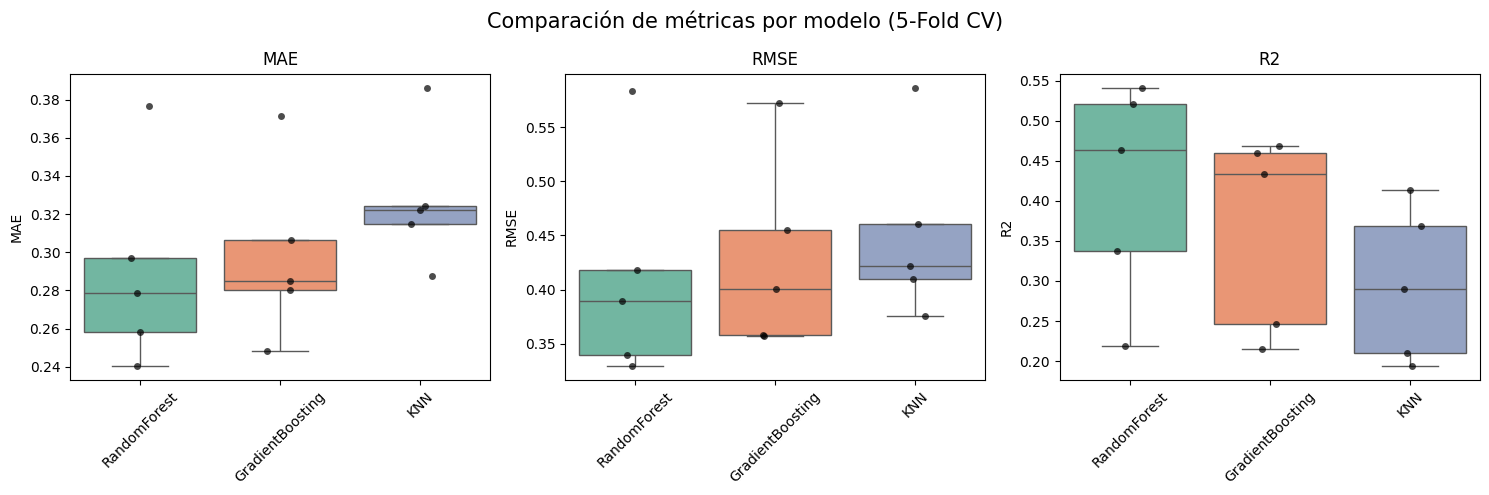

In [12]:
# Unificamos resultados en un solo dataframe
filas = []

for modelo, res in resultados.items():
    df = res["metricas"].copy().reset_index()   # recupera Fold como columna
    df["Modelo"] = modelo
    filas.append(df)

df_comparativo = pd.concat(filas, ignore_index=True)

metricas = ["MAE", "RMSE", "R2"]

modelos = df_comparativo["Modelo"].unique()

# Un color fijo por modelo
palette = dict(zip(modelos, sns.color_palette("Set2", n_colors=len(modelos))))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, metrica in zip(axes, metricas):

    sns.boxplot(
        data=df_comparativo,
        x="Modelo",
        y=metrica,
        hue="Modelo",
        order=modelos,
        hue_order=modelos,
        palette=palette,
        dodge=False,
        showfliers=False,
        legend=False,
        ax=ax
    )

    sns.stripplot(
        data=df_comparativo,
        x="Modelo",
        y=metrica,
        order=modelos,
        color="black",
        alpha=0.7,
        jitter=True,
        size=5,
        ax=ax
    )

    ax.set_title(metrica)
    ax.set_xlabel("")
    ax.set_ylabel(metrica)
    ax.tick_params(axis="x", rotation=45)

fig.suptitle("Comparación de métricas por modelo (5-Fold CV)", fontsize=15)
plt.tight_layout()
plt.show()

In [14]:
mejor_modelo = "RandomForest"
mejores_hyperparametros = {hiper.split("__")[1]: valor for hiper, valor in resultados[mejor_modelo]["hyperparams"].items()}

# Ajustamos el modelo
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(random_state=RANDOM_STATE, **mejores_hyperparametros))
])

final_model = pipeline.fit(X_train, y_train)

# Metricas de entrenamiento
print("Metricas de entrenamiento")
y_pred_train = final_model.predict(X_train)
print(f"MAE: {mean_absolute_error(y_train, y_pred_train):.3f}")
print(f"MSE: {mean_squared_error(y_train, y_pred_train):.3f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_train, y_pred_train)):.3f}")
print(f"R2: {r2_score(y_train, y_pred_train):.3f}")

# Evaluación final
y_pred = final_model.predict(X_test)

print("\nMetricas de test")
print(f"MAE: {mean_absolute_error(y_test, y_pred):.3f}")
print(f"MSE: {mean_squared_error(y_test, y_pred):.3f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.3f}")
print(f"R2: {r2_score(y_test, y_pred):.3f}")

Metricas de entrenamiento
MAE: 0.219
MSE: 0.096
RMSE: 0.310
R2: 0.676

Metricas de test
MAE: 0.288
MSE: 0.192
RMSE: 0.438
R2: 0.428


##### Usamos los predictores seleccionados en el EDA. La partición y la busqueda de hiperparametros se mantienen para comparar los resultados.

1. Carga de datos

In [15]:

df_ml = pd.read_csv(DATA_BASE_DIR / "milan_airbnb_completo_filtrado.csv")
X = df_ml.drop(columns=["daily_price", "log_daily_price"])
y = df_ml["log_daily_price"]

2. Division en entrenamiento y prueba

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

3. Preprocesamiento y algoritmo

In [17]:
preparador = ColumnTransformer([
    ("num", StandardScaler(), [col for col in numeric_features if col in X.columns]),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), [col for col in categorical_features if col in X.columns]),
    ("bin", "passthrough", [col for col in binary_features if col in X.columns]),
], remainder="drop")

candidatos = {"OLS": {"model": LinearRegression()}, **models_and_params}

4. Funcion de validación cruzada y evaluación de métricas

In [25]:
def validacion(X_tr, y_tr, X_te, y_te, n_iter, etiqueta):
    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    filas = []
    for nombre, config in candidatos.items():
        t0 = time.time()
        pipeline = Pipeline([
            ("preprocessor", clone(preparador)),
            ("regressor", clone(config["model"])),
        ])
        if "params" in config:
            ajuste = RandomizedSearchCV(
                pipeline, param_distributions=config["params"],
                n_iter=n_iter, scoring="neg_mean_squared_error",
                cv=cv, n_jobs=-1, random_state=42,
            ).fit(X_tr, y_tr)
            rmse_cv = (-ajuste.best_score_) ** 0.5
            mejores = ajuste.best_params_
        else:
            scores = cross_val_score(
                pipeline, X_tr, y_tr,
                scoring="neg_mean_squared_error", cv=cv,
            )
            rmse_cv = (-scores.mean()) ** 0.5
            ajuste = pipeline.fit(X_tr, y_tr)
            mejores = {}

        pred_tr, pred_te = ajuste.predict(X_tr), ajuste.predict(X_te)
        mse_te = mean_squared_error(y_te, pred_te)
        filas.append({
            "Corrida": etiqueta,
            "Modelo": nombre,
            "RMSE CV": rmse_cv,
            "RMSE train": mean_squared_error(y_tr, pred_tr) ** 0.5,
            "MAE test": mean_absolute_error(y_te, pred_te),
            "MSE test": mse_te,
            "RMSE test": mse_te ** 0.5,
            "R² test": r2_score(y_te, pred_te),
            "Tiempo (s)": round(time.time() - t0, 1),
            "Mejores params": mejores,
        })
    return pd.DataFrame(filas).sort_values("RMSE CV")

5. Evaluamos nuestro modelo

In [28]:
res_completa_12 = validacion(X_train, y_train, X_test, y_test, 12, "Completa (n_iter=12)")

res_muestra_12 = validacion(X_train_muestra, y_train_muestra,
                                X_test_muestra, y_test_muestra, 12, "Muestra (n_iter=12)")

res_completa_50 = validacion(X_train, y_train, X_test, y_test, 50, "Completa (n_iter=50)")

comparacion = pd.concat([res_completa_12, res_muestra_12, res_completa_50], ignore_index=True)
metricas = (comparacion.drop(columns="Mejores params")
            .sort_values(["Corrida", "RMSE CV"])
            .reset_index(drop=True))
display(metricas.round(4))

sin_ols = comparacion[comparacion["Modelo"] != "OLS"]
for modelo, g in sin_ols.groupby("Modelo"):
    det = pd.DataFrame(g["Mejores params"].tolist(), index=g.index)
    det.columns = [c.replace("regressor__", "") for c in det.columns]
    det.insert(0, "Corrida", g["Corrida"])
    print(f"\n=== {modelo} ===")
    display(det.round(4))

,Corrida,Modelo,RMSE CV,RMSE train,MAE test,MSE test,RMSE test,R² test,Tiempo (s)
0,Completa (n_iter=12),GradientBoosting,0.3901,0.3095,0.2594,0.1419,0.3767,0.5213,36.0
1,Completa (n_iter=12),RandomForest,0.4011,0.2373,0.2721,0.1560,0.3949,0.4740,56.2
2,Completa (n_iter=12),KNN,0.4200,0.0000,0.2978,0.1751,0.4184,0.4095,1.2
3,Completa (n_iter=12),OLS,0.4327,0.4302,0.2985,0.1758,0.4192,0.4072,0.1
4,Completa (n_iter=50),GradientBoosting,0.3883,0.2672,0.2582,0.1431,0.3783,0.5174,135.1
5,Completa (n_iter=50),RandomForest,0.4011,0.2022,0.2709,0.1550,0.3936,0.4774,191.0
6,Completa (n_iter=50),KNN,0.4200,0.0000,0.2978,0.1751,0.4184,0.4095,4.2
7,Completa (n_iter=50),OLS,0.4327,0.4302,0.2985,0.1758,0.4192,0.4072,0.1
8,Muestra (n_iter=12),OLS,0.4465,0.4152,0.2872,0.1516,0.3893,0.3695,0.1
9,Muestra (n_iter=12),RandomForest,0.4491,0.2916,0.2366,0.1113,0.3336,0.5370,5.4



=== GradientBoosting ===


,Corrida,learning_rate,max_depth,n_estimators,subsample
0,Completa (n_iter=12),0.0463,4,487,0.9769
6,Muestra (n_iter=12),0.0117,6,370,0.7824
8,Completa (n_iter=50),0.0219,6,466,0.8733



=== KNN ===


,Corrida,n_neighbors,p,weights
2,Completa (n_iter=12),17,1,distance
7,Muestra (n_iter=12),17,1,distance
10,Completa (n_iter=50),17,1,distance



=== RandomForest ===


,Corrida,max_depth,min_samples_leaf,min_samples_split,n_estimators
1,Completa (n_iter=12),18,2,8,150
5,Muestra (n_iter=12),15,4,6,120
9,Completa (n_iter=50),18,2,3,364


**Gradient Boosting** obtuvo el mejor desempeño (MAE 0.259, RMSE 0.377, R² 0.521), seguido por Random Forest (R² 0.474), KNN (0.410) y OLS (0.407). Los modelos de ensamble mejoran al modelo lineal, lo que indica relaciones no lineales entre las características del alojamiento y el precio.

Se aplicó validación cruzada de 5 folds sobre el entrenamiento y RandomizedSearchCV para ajustar los hiperparámetros. El sobreajuste se evaluó comparando el RMSE de entrenamiento y de prueba: fue máximo en KNN (0.000 contra 0.418, por el uso de ponderación por distancia), alto en Random Forest (0.237 contra 0.395), moderado en Gradient Boosting (0.310 contra 0.377) y nulo en OLS. El RMSE de validación cruzada (0.390 en Gradient Boosting) resultó muy cercano al de prueba (0.377), lo que indica que el resultado es estable.

Aumentar las iteraciones de la búsqueda de 12 a 50 no mejoró el desempeño en prueba (RMSE 0.377 contra 0.378 en Gradient Boosting) y aumentó el tiempo de cómputo de 36 a 135 segundos, porque la búsqueda eligió modelos más complejos que ajustaban mejor el entrenamiento pero no generalizaban mejor. Con la muestra de 750 registros los modelos de ensamble no superaron claramente al OLS en validación cruzada, y la mejora aparece al contar con más datos.